# Capitolo 11 — Rilevamento: geometria, selezione e AP

Arcangelo Distante e Cosimo Distante · **Computer Vision**

Non viene eseguito né addestrato un detector. Box, score e classi sono assegnati. La procedura AP è monoclasse, senza crowd o annotazioni ignorate, e non sostituisce l’evaluator COCO.

## Avvio in Google Colab o in locale

Aprire questo file in Colab e selezionare un runtime Python su CPU; non è richiesta una GPU. Usare **Esegui tutto** dall’inizio. Le dipendenze sono NumPy e Matplotlib, già normalmente presenti in Colab; in un ambiente locale installarle con `python -m pip install numpy matplotlib`.

I dati vengono costruiti nelle celle: non occorre caricare file, checkpoint o figure del libro. Per ripartire, riavviare il runtime ed eseguire tutte le celle in ordine. La cartella relativa `output_capitolo11` conserva JSON, CSV e figure; in Colab scaricarla prima di terminare la sessione. Le variabili intermedie non persistono dopo il riavvio.

Le istruzioni per Colab descrivono la procedura di avvio; non attribuiscono al servizio misure effettuate altrove.

In [1]:
from pathlib import Path
import json, platform
import numpy as np
import matplotlib.pyplot as plt

output = Path('output_capitolo11')
output.mkdir(exist_ok=True)
rng = np.random.default_rng(42)
plt.rcParams.update({'font.size': 11, 'figure.figsize': (7, 4)})
def salva_json(nome, dati):
    (output / nome).write_text(json.dumps(dati, indent=2, ensure_ascii=False,
        allow_nan=False, default=lambda v: np.asarray(v).tolist()), encoding='utf-8')
salva_json('ambiente.json', {'python': platform.python_version(), 'numpy': np.__version__,
                           'dispositivo': 'CPU', 'dati': 'sintetici autocontenuti'})
print('Output:', output)


Output: output_capitolo11


## A — Box e sovrapposizione

Le coordinate continue usano ordine xyxy e area senza +1. Controlliamo geometria e invarianza a una scala positiva comune.

{'IoU_AB': 0.3333333333333333, 'IoU_AD': 0.0, 'GIoU_AD': -0.2, 'IoU_AB_scala3': 0.3333333333333333}


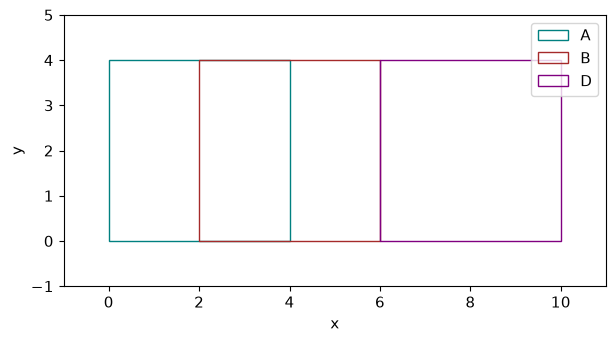

In [2]:
def area(b):
    b = np.asarray(b, dtype=float)
    return np.maximum(b[..., 2]-b[..., 0], 0)*np.maximum(b[..., 3]-b[..., 1], 0)
def iou(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    low, high = np.maximum(a[:2], b[:2]), np.minimum(a[2:], b[2:])
    inter = np.maximum(high-low, 0).prod()
    union = area(a)+area(b)-inter
    return float(inter/union) if union > 0 else 0.0
def giou(a, b):
    low, high = np.minimum(a[:2], b[:2]), np.maximum(a[2:], b[2:])
    cover = np.maximum(high-low, 0).prod()
    inter = np.maximum(np.minimum(a[2:], b[2:])-np.maximum(a[:2], b[:2]), 0).prod()
    union = area(a)+area(b)-inter
    return iou(a, b)-float((cover-union)/cover) if cover > 0 else 0.0
A = np.array([0., 0., 4., 4.]); B = np.array([2., 0., 6., 4.]); D = np.array([6., 0., 10., 4.])
geometria = {'IoU_AB': iou(A,B), 'IoU_AD': iou(A,D), 'GIoU_AD': giou(A,D),
            'IoU_AB_scala3': iou(3*A,3*B)}
assert np.isclose(geometria['IoU_AB'], 1/3)
assert np.isclose(geometria['GIoU_AD'], -.2)
print(geometria); salva_json('geometria.json', geometria)
fig, ax = plt.subplots()
for box, colore, nome in [(A,'teal','A'),(B,'brown','B'),(D,'purple','D')]:
    ax.add_patch(plt.Rectangle(box[:2], box[2]-box[0], box[3]-box[1], fill=False, color=colore, label=nome))
ax.set(xlim=(-1,11), ylim=(-1,5), xlabel='x', ylabel='y'); ax.set_aspect('equal'); ax.legend()
fig.savefig(output/'box.png', dpi=180, bbox_inches='tight'); plt.show()


### Interpretazione

N11.A.1 — Spiegare perché IoU(A,B) è 1/3 e perché la scala comune non cambia il risultato.

N11.A.2 — Perché GIoU(A,D) è negativa? Una loss 1−GIoU pari a 1.2 è ammissibile?

## B — Soppressione dei duplicati

NMS greedy ordina gli score; i pareggi sono risolti mediante l’indice iniziale. Il confronto è strettamente maggiore della soglia. La versione per classe confronta soltanto candidati della stessa categoria.

In [3]:
def nms(boxes, scores, labels, soglia, per_classe=True):
    order = list(np.argsort(-np.asarray(scores), kind='stable'))
    keep = []
    while order:
        k = order.pop(0); keep.append(int(k))
        order = [j for j in order if not ((not per_classe or labels[k] == labels[j])
                                        and iou(boxes[k],boxes[j]) > soglia)]
    return keep
boxes = np.stack([A,B,D]); scores = np.array([.9,.8,.7]); labels = np.array([1,2,1])
risultati_nms = {'agnostica': nms(boxes,scores,labels,.3,False),
                'per_classe': nms(boxes,scores,labels,.3,True)}
assert risultati_nms['agnostica'] == [0,2]
assert risultati_nms['per_classe'] == [0,1,2]
print(risultati_nms); salva_json('nms.json', risultati_nms)


{'agnostica': [0, 2], 'per_classe': [0, 1, 2]}


### Interpretazione

N11.B.1 — Quale IoU provoca la soppressione e quale informazione cambia fra le due modalità?

N11.B.2 — Perché NMS non può stabilire se una box è un vero positivo?

## C — Matching e integrazione della precision

Le GT sono due e non possono essere occupate due volte. Si confrontano soglie IoU 0.5 e 0.8, mantenendo invariati score e predizioni. AP all-points e AP a 101 punti sono definite esplicitamente.

In [4]:
def valuta(boxes, scores, gt, soglia):
    order = np.argsort(-np.asarray(scores), kind='stable'); used = np.zeros(len(gt),bool)
    tp = []
    for k in order:
        overlaps = np.array([iou(boxes[k],g) if not used[j] else -1 for j,g in enumerate(gt)])
        best = int(np.argmax(overlaps)); ok = overlaps[best] >= soglia
        tp.append(int(ok))
        if ok: used[best] = True
    tp = np.array(tp); precision = np.cumsum(tp)/np.arange(1,len(tp)+1)
    recall = np.cumsum(tp)/len(gt)
    r = np.r_[0.,recall,1.]; p = np.r_[0.,precision,0.]
    envelope = np.maximum.accumulate(p[::-1])[::-1]
    ap = float(np.sum(np.diff(r)*envelope[1:]))
    ap101 = float(np.mean([max(precision[recall >= x], default=0.) for x in np.linspace(0,1,101)]))
    return {'TP':tp,'precision':precision,'recall':recall,'AP':ap,'AP101':ap101}
pred = np.array([[.5,0,4.5,4],[0,0,4,4],[6,0,10,4]],float)
gt = np.stack([A,D]); metriche = {}
for threshold in [.5,.8]:
    m = valuta(pred, [.9,.8,.7], gt, threshold); metriche[str(threshold)] = m
    np.savetxt(output/f'ranking_iou{threshold}.csv', np.column_stack([m['TP'],m['precision'],m['recall']]),
               delimiter=',',header='TP,precision,recall',comments='')
    print(threshold, m)
assert np.isclose(metriche['0.5']['AP'], 5/6)
assert np.isclose(metriche['0.8']['AP'], 2/3)
salva_json('metriche.json', metriche)


0.5 {'TP': array([1, 0, 1]), 'precision': array([1.        , 0.5       , 0.66666667]), 'recall': array([0.5, 0.5, 1. ]), 'AP': 0.8333333333333333, 'AP101': 0.8349834983498351}
0.8 {'TP': array([0, 1, 1]), 'precision': array([0.        , 0.5       , 0.66666667]), 'recall': array([0. , 0.5, 1. ]), 'AP': 0.6666666666666666, 'AP101': 0.6666666666666669}


### Interpretazione

N11.C.1 — Ricostruire i due ranking TP/FP e spiegare il diverso valore di AP.

N11.C.2 — Perché AP all-points e AP101 non coincidono esattamente alla soglia 0.5?

## Conservare e interpretare gli output

Controllare i file nella cartella di output e scaricarli insieme al notebook se si usa un runtime temporaneo. JSON e CSV distinguono valori analitici assegnati, campioni sintetici e risultati dei calcoli. Le verifiche numeriche non stimano le prestazioni dei modelli reali. Per studiarli occorrono pesi, dati, licenze e un protocollo separato.

## Risorse primarie e implementazioni ufficiali

- [Faster R-CNN](https://arxiv.org/abs/1506.01497)

- [DETR, codice degli autori](https://github.com/facebookresearch/detr)

- [COCO API](https://github.com/cocodataset/cocoapi)